# Milstolpe 5 – Från rådata till svar

## 1. Standardisering

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    FunctionTransformer
)

from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve
)

from sklearn.model_selection import (
    cross_val_score,
    StratifiedKFold
)

Dataset successfully loaded!
Number of games: 124146
Number of columns: 41
Dataset columns:
['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'dlc_count', 'detailed_description', 'short_description', 'supported_languages', 'full_audio_languages', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'screenshots', 'movies', 'packages']

Data types:
appID                           str
name                            str
release_date                    str
estimated_owners                str
peak_ccu                      int64
required_age                  int64
price                       float64
dlc_count  

Series([], dtype: int64)


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 124146 entries, 0 to 124145
Data columns (total 41 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   appID                     124146 non-null  str    
 1   name                      124146 non-null  str    
 2   release_date              124146 non-null  str    
 3   estimated_owners          124146 non-null  str    
 4   peak_ccu                  124146 non-null  int64  
 5   required_age              124146 non-null  int64  
 6   price                     124146 non-null  float64
 7   dlc_count                 124146 non-null  int64  
 8   detailed_description      124146 non-null  str    
 9   short_description         124146 non-null  str    
 10  supported_languages       124146 non-null  object 
 11  full_audio_languages      124146 non-null  object 
 12  reviews                   124146 non-null  str    
 13  header_image              124146 

,peak_ccu,required_age,price,dlc_count,metacritic_score,user_score,positive,negative,achievements,recommendations,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks
count,1.241460e+05,124146.000000,124146.000000,124146.000000,124146.000000,124146.000000,1.241460e+05,1.241460e+05,124146.000000,1.241460e+05,1.241460e+05,124146.000000,1.241460e+05,124146.000000
mean,5.391834e+01,0.166151,4.786144,0.540573,2.533855,0.024246,1.032103e+03,1.671155e+02,18.010520,9.501171e+02,2.054626e+02,13.628204,1.714364e+02,14.550578
std,3.706328e+03,1.646332,12.507614,14.426264,13.580489,1.386253,2.791776e+04,5.341348e+03,140.633042,2.174339e+04,1.114814e+04,268.710314,1.113308e+04,292.692992
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.000000e+00,0.000000,0.550000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
50%,0.000000e+00,0.000000,2.390000,0.000000,0.000000,0.000000,5.000000e+00,1.000000e+00,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
75%,0.000000e+00,0.000000,5.390000,0.000000,0.000000,0.000000,3.600000e+01,1.000000e+01,19.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
max,1.013936e+06,21.000000,999.980000,3703.000000,97.000000,100.000000,7.642084e+06,1.173003e+06,9821.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000


ALL DATASET COLUMNS

appID                               str
name                                str
release_date                        str
estimated_owners                    str
peak_ccu                            int64
required_age                        int64
price                               float64
dlc_count                           int64
detailed_description                str
short_description                   str
supported_languages                 object
full_audio_languages                object
reviews                             str
header_image                        str
website                             str
support_url                         str
support_email                       str
windows                             bool
mac                                 bool
linux                               bool
metacritic_score                    int64
metacritic_url                      str
user_score                          int64
positive                            

,name,release_date,estimated_owners,peak_ccu,price,metacritic_score,user_score,positive,negative,recommendations,average_playtime_forever,genres,categories
0,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0.00,0,0,0,0,0,0,[],[]
1,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,5.24,0,0,252,3,231,8,[Adventure],"[Single-player, Steam Trading Cards, Steam Clo..."
2,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,4.99,0,0,21,3,0,0,[Casual],"[Single-player, Family Sharing]"
3,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,8.99,0,0,0,0,0,0,"[Casual, Indie, Simulation]","[Single-player, Steam Achievements, Family Sha..."
4,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,4.99,0,0,0,0,0,0,"[Action, Early Access]","[Single-player, VR Only, Steam Leaderboards, F..."
5,Agony VR,"Apr 5, 2023",0 - 20000,0,13.99,0,0,0,0,0,0,"[Action, Adventure]","[Single-player, Tracked Controller Support, VR..."
6,Armored Brigade II,"Apr 8, 2025",0 - 20000,8,35.99,0,0,117,13,107,675,"[Simulation, Strategy]","[Single-player, Steam Workshop, Steam Cloud, F..."
7,Galacatraz: Eject Equip Escape,"Feb 1, 2018",0 - 20000,0,0.99,0,0,0,0,0,0,"[Action, Indie]","[Single-player, Full controller support, Famil..."
8,Hepta Beats,"May 7, 2021",0 - 20000,0,0.99,0,0,28,4,0,0,"[Casual, Indie]","[Single-player, Steam Achievements, Full contr..."
9,MUMBA IV: Egypt Jewels,"Dec 13, 2021",0 - 20000,1,0.59,0,0,19,6,0,0,"[Action, Casual, Indie, Strategy]","[Single-player, Steam Achievements, Full contr..."


... (5 outputs left out)

,name,price,positive
68275,The Leverage Game,999.98,1
34463,Ascent Free-Roaming VR Experience,999.00,6
31935,True Love,500.00,3
85479,Aartform Curvy 3D 3.0,299.90,32
18915,Berries Challenge,199.99,9


Flest DLC:


,name,dlc_count,positive
122448,Fantasy Grounds VTT,3703,730
81495,Fantasy Grounds Classic,2006,978
97884,RPG Maker MV,1066,7542
81801,Rocksmith® 2014 Edition REMASTERED LEARN & PLAY,967,21217
83990,Train Simulator Classic,782,20015


genres                 5.2% tomma
categories             5.7% tomma
tags                   100.0% tomma
supported_languages    5.2% tomma
developers             5.2% tomma
publishers             5.6% tomma
short_description      5.1% tomma
detailed_description   5.2% tomma
website                56.0% tomma
Andel tomma spel: 5.1%
Andel hits bland tomma spel: 0.0%
Andel hits bland övriga: 26.3%


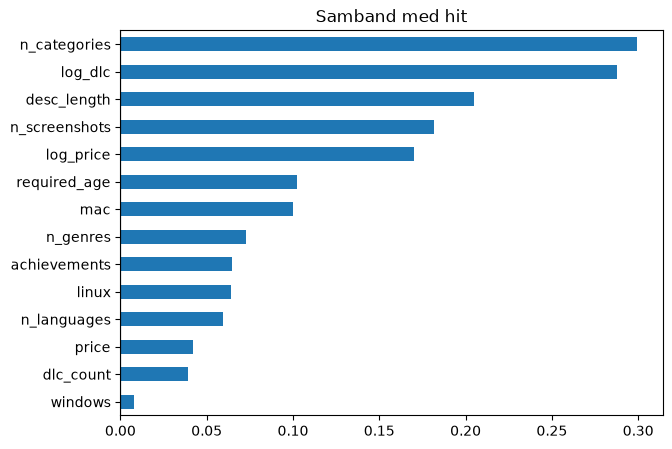

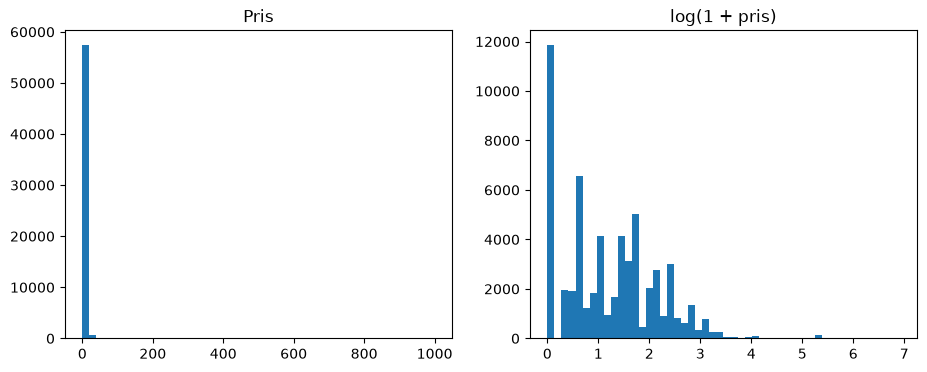

Dataset successfully loaded!
Number of games: 124146
Number of columns: 41
Dataset columns:
['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'dlc_count', 'detailed_description', 'short_description', 'supported_languages', 'full_audio_languages', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'screenshots', 'movies', 'packages']

Data types:
appID                           str
name                            str
release_date                    str
estimated_owners                str
peak_ccu                      int64
required_age                  int64
price                       float64
dlc_count  

Series([], dtype: int64)


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 124146 entries, 0 to 124145
Data columns (total 41 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   appID                     124146 non-null  str    
 1   name                      124146 non-null  str    
 2   release_date              124146 non-null  str    
 3   estimated_owners          124146 non-null  str    
 4   peak_ccu                  124146 non-null  int64  
 5   required_age              124146 non-null  int64  
 6   price                     124146 non-null  float64
 7   dlc_count                 124146 non-null  int64  
 8   detailed_description      124146 non-null  str    
 9   short_description         124146 non-null  str    
 10  supported_languages       124146 non-null  object 
 11  full_audio_languages      124146 non-null  object 
 12  reviews                   124146 non-null  str    
 13  header_image              124146 

,peak_ccu,required_age,price,dlc_count,metacritic_score,user_score,positive,negative,achievements,recommendations,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks
count,1.241460e+05,124146.000000,124146.000000,124146.000000,124146.000000,124146.000000,1.241460e+05,1.241460e+05,124146.000000,1.241460e+05,1.241460e+05,124146.000000,1.241460e+05,124146.000000
mean,5.391834e+01,0.166151,4.786144,0.540573,2.533855,0.024246,1.032103e+03,1.671155e+02,18.010520,9.501171e+02,2.054626e+02,13.628204,1.714364e+02,14.550578
std,3.706328e+03,1.646332,12.507614,14.426264,13.580489,1.386253,2.791776e+04,5.341348e+03,140.633042,2.174339e+04,1.114814e+04,268.710314,1.113308e+04,292.692992
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
25%,0.000000e+00,0.000000,0.550000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
50%,0.000000e+00,0.000000,2.390000,0.000000,0.000000,0.000000,5.000000e+00,1.000000e+00,2.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
75%,0.000000e+00,0.000000,5.390000,0.000000,0.000000,0.000000,3.600000e+01,1.000000e+01,19.000000,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000
max,1.013936e+06,21.000000,999.980000,3703.000000,97.000000,100.000000,7.642084e+06,1.173003e+06,9821.000000,4.830455e+06,3.429544e+06,20088.000000,3.429544e+06,20088.000000


ALL DATASET COLUMNS

appID                               str
name                                str
release_date                        str
estimated_owners                    str
peak_ccu                            int64
required_age                        int64
price                               float64
dlc_count                           int64
detailed_description                str
short_description                   str
supported_languages                 object
full_audio_languages                object
reviews                             str
header_image                        str
website                             str
support_url                         str
support_email                       str
windows                             bool
mac                                 bool
linux                               bool
metacritic_score                    int64
metacritic_url                      str
user_score                          int64
positive                            

,name,release_date,estimated_owners,peak_ccu,price,metacritic_score,user_score,positive,negative,recommendations,average_playtime_forever,genres,categories
0,Black Dragon Mage Playtest,"Aug 1, 2023",0 - 0,0,0.00,0,0,0,0,0,0,[],[]
1,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0 - 20000,0,5.24,0,0,252,3,231,8,[Adventure],"[Single-player, Steam Trading Cards, Steam Clo..."
2,Mystery Solitaire The Black Raven,"May 6, 2019",0 - 20000,0,4.99,0,0,21,3,0,0,[Casual],"[Single-player, Family Sharing]"
3,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0 - 20000,1,8.99,0,0,0,0,0,0,"[Casual, Indie, Simulation]","[Single-player, Steam Achievements, Family Sha..."
4,Maze Quest VR,"Apr 24, 2025",0 - 20000,0,4.99,0,0,0,0,0,0,"[Action, Early Access]","[Single-player, VR Only, Steam Leaderboards, F..."
5,Agony VR,"Apr 5, 2023",0 - 20000,0,13.99,0,0,0,0,0,0,"[Action, Adventure]","[Single-player, Tracked Controller Support, VR..."
6,Armored Brigade II,"Apr 8, 2025",0 - 20000,8,35.99,0,0,117,13,107,675,"[Simulation, Strategy]","[Single-player, Steam Workshop, Steam Cloud, F..."
7,Galacatraz: Eject Equip Escape,"Feb 1, 2018",0 - 20000,0,0.99,0,0,0,0,0,0,"[Action, Indie]","[Single-player, Full controller support, Famil..."
8,Hepta Beats,"May 7, 2021",0 - 20000,0,0.99,0,0,28,4,0,0,"[Casual, Indie]","[Single-player, Steam Achievements, Full contr..."
9,MUMBA IV: Egypt Jewels,"Dec 13, 2021",0 - 20000,1,0.59,0,0,19,6,0,0,"[Action, Casual, Indie, Strategy]","[Single-player, Steam Achievements, Full contr..."


SAMPLE OF 15 GAMES


,name,release_date,estimated_owners,positive,negative,recommendations,genres
43132,Tentacult!,"Sep 23, 2016",0 - 20000,29,7,0,"[Adventure, Casual, Indie]"
104209,Gunship Recon,"May 8, 2019",0 - 20000,0,2,0,"[Action, Indie]"
82769,Angvik,"Feb 24, 2014",100000 - 200000,2194,309,2092,"[Action, Indie]"
60248,The Warrens,"Oct 30, 2025",0 - 20000,0,0,0,"[Action, Indie]"
30515,Steel Century Groove: Midnight,"Mar 5, 2025",0 - 0,0,0,0,"[Action, Adventure, RPG, Free To Play]"
37657,NoFlash,"May 12, 2025",0 - 0,0,0,0,[Free To Play]
29979,No Clue VR,"Nov 7, 2017",0 - 20000,15,8,0,"[Action, Casual, Indie, Simulation]"
74414,DropTunnel Playtest,"Nov 1, 2025",0 - 0,0,0,0,[]
81390,Soaked Playtest,"Apr 3, 2025",0 - 0,0,0,0,[]
71087,Ellen,"Feb 15, 2019",0 - 20000,23,4,0,"[Adventure, Casual, Indie]"



RELEASE DATE EXAMPLES
['Aug 1, 2023', 'Jul 29, 2016', 'May 6, 2019', 'Oct 31, 2024', 'Apr 24, 2025', 'Apr 5, 2023', 'Apr 8, 2025', 'Feb 1, 2018', 'May 7, 2021', 'Dec 13, 2021', 'Mar 25, 2022', 'Sep 25, 2019', 'Sep 5, 2019', 'Apr 5, 2023', 'Apr 19, 2024', 'Apr 29, 2020', 'Aug 10, 2023', 'Oct 23, 2014', 'Jan 9, 2023', 'Jul 28, 2023']

ESTIMATED OWNERS EXAMPLES
estimated_owners
0 - 20000                75545
0 - 0                    23033
20000 - 50000            11397
50000 - 100000            5355
100000 - 200000           3454
200000 - 500000           2854
500000 - 1000000          1154
1000000 - 2000000          729
2000000 - 5000000          405
5000000 - 10000000         125
10000000 - 20000000         51
20000000 - 50000000         31
50000000 - 100000000         9
100000000 - 200000000        4
Name: count, dtype: int64

REVIEW STATISTICS


,positive,negative
count,1.241460e+05,1.241460e+05
mean,1.032103e+03,1.671155e+02
std,2.791776e+04,5.341348e+03
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,5.000000e+00,1.000000e+00
75%,3.600000e+01,1.000000e+01
max,7.642084e+06,1.173003e+06


Antal spel kvar: 97528
hit
0    73154
1    24374
Name: count, dtype: int64
Träning: 58516
Validering: 19506
Test: 19506
Removed from training: 2966
Removed from validation: 1032
Removed from testing: 975
n_movies
0    55550
Name: count, dtype: int64


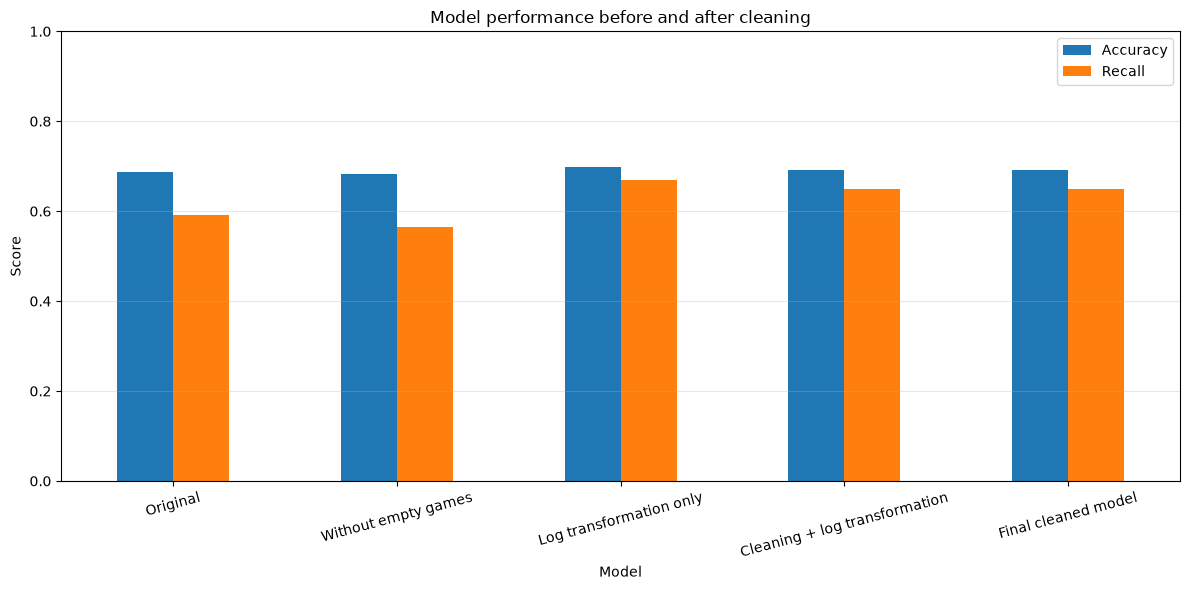

In [2]:
%run 02_know_the_data.ipynb

In [3]:
print("Training:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)

print(df_train.columns.tolist())

Training: (55550, 50)
Validation: (18474, 50)
Test: (18531, 50)
['appID', 'name', 'release_date', 'estimated_owners', 'peak_ccu', 'required_age', 'price', 'dlc_count', 'detailed_description', 'short_description', 'supported_languages', 'full_audio_languages', 'reviews', 'header_image', 'website', 'support_url', 'support_email', 'windows', 'mac', 'linux', 'metacritic_score', 'metacritic_url', 'user_score', 'positive', 'negative', 'score_rank', 'achievements', 'recommendations', 'notes', 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'developers', 'publishers', 'categories', 'genres', 'tags', 'screenshots', 'movies', 'packages', 'release_year', 'hit', 'n_screenshots', 'n_movies', 'desc_length', 'has_website', 'log_dlc', 'log_achievements', 'log_desc_length']


In [4]:
def add_features(d):
    d = d.copy()

    d["log_dlc"] = np.log1p(d["dlc_count"])

    d["log_achievements"] = np.log1p(
        d["achievements"]
    )

    d["n_screenshots"] = d["screenshots"].apply(len)

    d["log_desc_length"] = np.log1p(
        d["detailed_description"].fillna("").str.len()
    )

    d["has_website"] = (
        d["website"].fillna("").str.strip() != ""
    ).astype(int)

    d["n_categories"] = d["categories"].apply(len)

    d["is_free"] = (d["price"] == 0).astype(int)

    d["genre_Casual"] = d["genres"].apply(
        lambda g: int("Casual" in g)
    )

    for kat in [
        "Steam Cloud",
        "Remote Play on TV",
        "Steam Workshop",
        "Remote Play Together",
        "Shared/Split Screen"
    ]:
        d["category_" + kat] = d["categories"].apply(
            lambda c: int(kat in c)
        )

    d["release_month"] = (
        pd.to_datetime(
            d["release_date"],
            format="mixed",
            errors="coerce"
        )
        .dt.month
        .fillna(0)
        .astype(int)
        .astype(str)
    )

    d["short_description"] = (
        d["short_description"].fillna("")
    )

    return d

In [5]:
numeric_features = [
    "log_dlc",
    "log_achievements",
    "n_screenshots",
    "log_desc_length",
    "n_categories",
    "required_age"
]

binary_features = [
    "has_website",
    "category_Steam Cloud",
    "category_Remote Play on TV",
    "category_Steam Workshop",
    "genre_Casual",
    "is_free",
    "category_Remote Play Together",
    "category_Shared/Split Screen"
]

base_features = numeric_features + binary_features

train = add_features(df_train)
val = add_features(df_val)

y_train = train["hit"]
y_val = val["hit"]

print(base_features)
print("Features:", len(base_features))

['log_dlc', 'log_achievements', 'n_screenshots', 'log_desc_length', 'n_categories', 'required_age', 'has_website', 'category_Steam Cloud', 'category_Remote Play on TV', 'category_Steam Workshop', 'genre_Casual', 'is_free', 'category_Remote Play Together', 'category_Shared/Split Screen']
Features: 14


In [6]:
baseline_model = LogisticRegression(
    max_iter=3000
)

baseline_model.fit(
    train[base_features],
    y_train
)

baseline_pred = baseline_model.predict(
    val[base_features]
)

baseline_f1 = f1_score(y_val, baseline_pred)

print("Milestone 4 F1:", round(baseline_f1, 4))

Milestone 4 F1: 0.4397


In [7]:
scaler = StandardScaler()

train_scaled = train[base_features].copy()
val_scaled = val[base_features].copy()

train_scaled[numeric_features] = (
    scaler.fit_transform(train[numeric_features])
)

val_scaled[numeric_features] = (
    scaler.transform(val[numeric_features])
)

scaled_model = LogisticRegression(max_iter=3000)

scaled_model.fit(train_scaled, y_train)

scaled_pred = scaled_model.predict(val_scaled)

scaled_f1 = f1_score(y_val, scaled_pred)

print("Original F1:", round(baseline_f1, 4))
print("Standardised F1:", round(scaled_f1, 4))

Original F1: 0.4397
Standardised F1: 0.4396


## 2. One-hot encoding

In [8]:
train["release_month"].value_counts().sort_index()

release_month
1     3700
10    5469
11    5214
12    4921
2     4223
3     4417
4     4192
5     4673
6     4194
7     4654
8     4964
9     4929
Name: count, dtype: int64

In [9]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

train_month = encoder.fit_transform(
    train[["release_month"]]
)

val_month = encoder.transform(
    val[["release_month"]]
)

X_train_month = np.hstack([
    train_scaled.to_numpy(),
    train_month
])

X_val_month = np.hstack([
    val_scaled.to_numpy(),
    val_month
])

month_model = LogisticRegression(max_iter=3000)

month_model.fit(X_train_month, y_train)

month_pred = month_model.predict(X_val_month)

month_f1 = f1_score(y_val, month_pred)

print("Standardised F1:", round(scaled_f1, 4))
print("One-hot F1:", round(month_f1, 4))

Standardised F1: 0.4396
One-hot F1: 0.4369


## 3. TF-IDF på butikstexten

In [11]:
def make_preprocessor(
    scale=False,
    month=False,
    text=False,
    stop_words="english"
):
    transformers = [
        (
            "numeric",
            StandardScaler() if scale else "passthrough",
            numeric_features
        ),
        (
            "binary",
            "passthrough",
            binary_features
        )
    ]

    if month:
        transformers.append((
            "month",
            OneHotEncoder(handle_unknown="ignore"),
            ["release_month"]
        ))

    if text:
        transformers.append((
            "text",
            TfidfVectorizer(
                max_features=5000,
                min_df=5,
                stop_words=stop_words
            ),
            "short_description"
        ))

    return ColumnTransformer(
        transformers,
        sparse_threshold=1.0
    )

In [12]:
text_preprocessor = make_preprocessor(
    scale=True,
    month=True,
    text=True
)

X_train_text = text_preprocessor.fit_transform(train)
X_val_text = text_preprocessor.transform(val)

text_model = LogisticRegression(max_iter=3000)

text_model.fit(X_train_text, y_train)

text_pred = text_model.predict(X_val_text)

text_f1 = f1_score(y_val, text_pred)

print("One-hot F1:", round(month_f1, 4))
print("TF-IDF F1:", round(text_f1, 4))

print("Matrix shape:", X_train_text.shape)
print("Matrix type:", type(X_train_text))

One-hot F1: 0.4369
TF-IDF F1: 0.5058
Matrix shape: (55550, 5026)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


In [13]:
suspect_words = [
    "award",
    "awards",
    "award-winning",
    "acclaimed",
    "bestselling",
    "best-selling",
    "million",
    "reviews",
    "reviewed",
    "rated",
    "popular",
    "successful"
]

leakage_results = []

overall_hit_rate = y_train.mean()

for word in suspect_words:

    mask = train["short_description"].str.contains(
        rf"\b{word}\b",
        case=False,
        regex=True,
        na=False
    )

    count = mask.sum()

    if count > 0:
        hit_rate = train.loc[mask, "hit"].mean()

        leakage_results.append({
            "Word": word,
            "Games": count,
            "Hit rate": hit_rate,
            "Overall hit rate": overall_hit_rate,
            "Difference": hit_rate - overall_hit_rate
        })

leakage_table = pd.DataFrame(leakage_results)

leakage_table.sort_values(
    "Difference",
    ascending=False
).round(4)

,Word,Games,Hit rate,Overall hit rate,Difference
1,awards,34,0.7353,0.2633,0.4720
3,acclaimed,151,0.6887,0.2633,0.4255
9,rated,18,0.6667,0.2633,0.4034
2,award-winning,202,0.5693,0.2633,0.3060
6,million,91,0.5604,0.2633,0.2972
5,best-selling,26,0.5385,0.2633,0.2752
7,reviews,15,0.5333,0.2633,0.2701
0,award,291,0.5292,0.2633,0.2660
4,bestselling,10,0.5000,0.2633,0.2367
10,popular,282,0.3404,0.2633,0.0772


In [14]:
excluded_words = [
    "award",
    "awards",
    "acclaimed",
    "bestselling",
    "reviews",
    "reviewed",
    "rated"
]

filtered_stop_words = sorted(
    set(ENGLISH_STOP_WORDS).union(excluded_words)
)

filtered_preprocessor = make_preprocessor(
    scale=True,
    month=True,
    text=True,
    stop_words=filtered_stop_words
)

X_train_filtered = filtered_preprocessor.fit_transform(
    train
)

X_val_filtered = filtered_preprocessor.transform(val)

filtered_model = LogisticRegression(max_iter=3000)

filtered_model.fit(X_train_filtered, y_train)

filtered_pred = filtered_model.predict(X_val_filtered)

filtered_f1 = f1_score(y_val, filtered_pred)

print("Original TF-IDF F1:", round(text_f1, 4))
print("Filtered TF-IDF F1:", round(filtered_f1, 4))

Original TF-IDF F1: 0.5058
Filtered TF-IDF F1: 0.5047


In [15]:
validation_results = pd.DataFrame({
    "Model": [
        "Milestone 4",
        "StandardScaler",
        "StandardScaler + OneHot",
        "TF-IDF",
        "Filtered TF-IDF"
    ],
    "F1": [
        baseline_f1,
        scaled_f1,
        month_f1,
        text_f1,
        filtered_f1
    ]
})

validation_results["F1 improvement"] = (
    validation_results["F1"] - baseline_f1
)

validation_results.round(4)

,Model,F1,F1 improvement
0,Milestone 4,0.4397,0.0000
1,StandardScaler,0.4396,-0.0001
2,StandardScaler + OneHot,0.4369,-0.0028
3,TF-IDF,0.5058,0.0661
4,Filtered TF-IDF,0.5047,0.0650


## 4. En pipeline

In [16]:
def make_pipeline(
    scale=False,
    month=False,
    text=False,
    stop_words="english"
):
    return Pipeline([
        (
            "features",
            FunctionTransformer(
                add_features,
                validate=False
            )
        ),
        (
            "preprocessing",
            make_preprocessor(
                scale=scale,
                month=month,
                text=text,
                stop_words=stop_words
            )
        ),
        (
            "model",
            LogisticRegression(max_iter=3000)
        )
    ])

In [17]:
pipeline = make_pipeline(
    scale=True,
    month=True,
    text=True,
    stop_words=filtered_stop_words
)

pipeline.fit(df_train, y_train)

pipeline_pred = pipeline.predict(df_val)

pipeline_f1 = f1_score(y_val, pipeline_pred)

print("Manual F1:", round(filtered_f1, 4))
print("Pipeline F1:", round(pipeline_f1, 4))

print(
    "Identical predictions:",
    np.array_equal(filtered_pred, pipeline_pred)
)

Manual F1: 0.5047
Pipeline F1: 0.5047
Identical predictions: True


In [18]:
new_game = pd.DataFrame([{
    "name": "Pixel Harbor Adventure",
    "price": 19.99,
    "required_age": 0,
    "dlc_count": 0,
    "achievements": 30,
    "screenshots": ["image"] * 10,
    "website": "https://example.com",
    "genres": ["Adventure", "Indie", "Casual"],
    "categories": [
        "Single-player",
        "Steam Cloud",
        "Steam Achievements"
    ],
    "release_date": "Jun 15, 2027",
    "short_description":
        "Explore a mysterious island and solve puzzles.",
    "detailed_description":
        "An adventure game with exploration, puzzles "
        "and an immersive story."
}])

probability = pipeline.predict_proba(new_game)[0, 1]

print("Game:", new_game["name"].iloc[0])
print(f"Hit probability: {probability:.2%}")

Game: Pixel Harbor Adventure
Hit probability: 40.90%


## 5. Korsvalidering

In [20]:
models = {
    "Milestone 4": make_pipeline(),

    "StandardScaler": make_pipeline(
        scale=True
    ),

    "StandardScaler + OneHot": make_pipeline(
        scale=True,
        month=True
    ),

    "TF-IDF": make_pipeline(
        scale=True,
        month=True,
        text=True
    ),

    "Filtered TF-IDF": make_pipeline(
        scale=True,
        month=True,
        text=True,
        stop_words=filtered_stop_words
    )
}

In [21]:
X_cv = pd.concat(
    [df_train, df_val],
    ignore_index=True
)

y_cv = X_cv["hit"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for name, candidate_model in models.items():

    print("Evaluating:", name, flush=True)

    scores = cross_val_score(
        candidate_model,
        X_cv,
        y_cv,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean F1": scores.mean(),
        "Std": scores.std()
    })

    print("Mean F1:", round(scores.mean(), 4))
    print("Std:", round(scores.std(), 4))

cv_table = pd.DataFrame(cv_results)

cv_table.round(4)

Evaluating: Milestone 4
Mean F1: 0.443
Std: 0.0101
Evaluating: StandardScaler
Mean F1: 0.4429
Std: 0.01
Evaluating: StandardScaler + OneHot
Mean F1: 0.4414
Std: 0.0102
Evaluating: TF-IDF
Mean F1: 0.5025
Std: 0.0107
Evaluating: Filtered TF-IDF
Mean F1: 0.5026
Std: 0.0111


,Model,Mean F1,Std
0,Milestone 4,0.4430,0.0101
1,StandardScaler,0.4429,0.0100
2,StandardScaler + OneHot,0.4414,0.0102
3,TF-IDF,0.5025,0.0107
4,Filtered TF-IDF,0.5026,0.0111


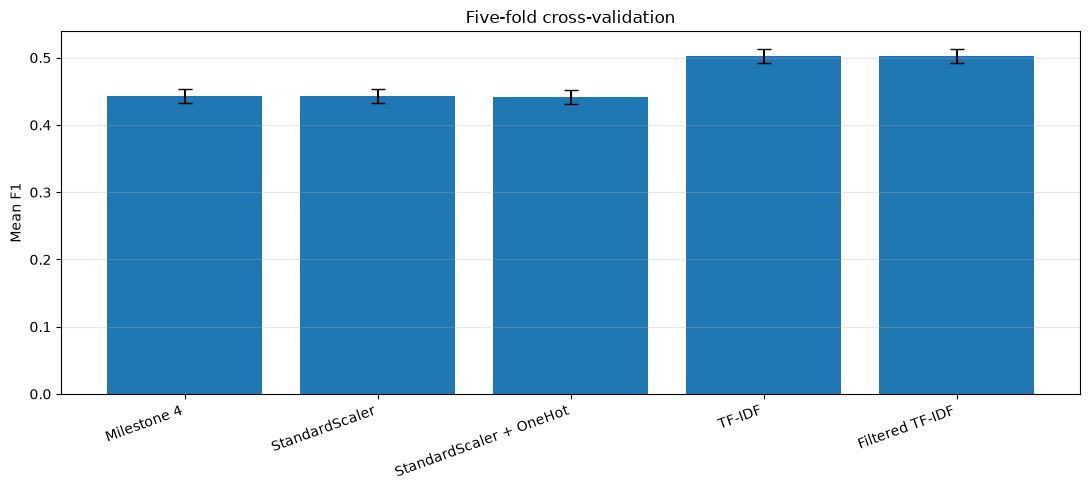

In [22]:
plt.figure(figsize=(11, 5))

plt.bar(
    cv_table["Model"],
    cv_table["Mean F1"],
    yerr=cv_table["Std"],
    capsize=5
)

plt.ylabel("Mean F1")
plt.title("Five-fold cross-validation")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
best_row = cv_table.loc[
    cv_table["Mean F1"].idxmax()
]

cv_table["Difference from best"] = (
    best_row["Mean F1"] - cv_table["Mean F1"]
)

cv_table["Within best model std"] = (
    cv_table["Difference from best"] <= best_row["Std"]
)

cv_table.round(4)

,Model,Mean F1,Std,Difference from best,Within best model std
0,Milestone 4,0.4430,0.0101,0.0596,False
1,StandardScaler,0.4429,0.0100,0.0597,False
2,StandardScaler + OneHot,0.4414,0.0102,0.0612,False
3,TF-IDF,0.5025,0.0107,0.0000,True
4,Filtered TF-IDF,0.5026,0.0111,0.0000,True


## 6. Tröskelvärde och test

In [24]:
from sklearn.base import clone

# Replace with the chosen model after reviewing CV.
chosen_model_name = "Filtered TF-IDF"

final_pipeline = clone(models[chosen_model_name])

final_pipeline.fit(df_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocessing', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](50,)","['appID','name','release_date',...,'log_dlc','log_achievements', 'log_desc_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,50
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...002073B1BC510>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False


In [25]:
val_proba = final_pipeline.predict_proba(
    df_val
)[:, 1]

threshold_results = []

for t in np.arange(0.05, 1.0, 0.05):

    pred = (val_proba >= t).astype(int)

    threshold_results.append({
        "Threshold": t,
        "Precision": precision_score(
            y_val, pred, zero_division=0
        ),
        "Recall": recall_score(y_val, pred),
        "F1": f1_score(y_val, pred),
        "Accepted games": pred.sum(),
        "Accepted share": pred.mean()
    })

threshold_table = pd.DataFrame(threshold_results)

threshold_table.round(4)

,Threshold,Precision,Recall,F1,Accepted games,Accepted share
0,0.05,0.2892,0.9815,0.4468,16542,0.8954
1,0.10,0.3408,0.9268,0.4983,13256,0.7175
2,0.15,0.3911,0.8494,0.5356,10585,0.5730
3,0.20,0.4380,0.7655,0.5572,8519,0.4611
4,0.25,0.4822,0.6910,0.5681,6984,0.3780
5,0.30,0.5219,0.6268,0.5695,5854,0.3169
6,0.35,0.5609,0.5648,0.5629,4908,0.2657
7,0.40,0.5912,0.5016,0.5427,4136,0.2239
8,0.45,0.6330,0.4547,0.5292,3501,0.1895
9,0.50,0.6702,0.4048,0.5047,2944,0.1594


In [26]:
funding_capacity = 0.10

antal = int(len(val_proba) * funding_capacity)

TROSKEL = float(
    pd.Series(val_proba).nlargest(antal).min()
)

val_final_pred = (val_proba >= TROSKEL).astype(int)

print("Threshold:", round(TROSKEL, 4))

print("Precision:", round(
    precision_score(y_val, val_final_pred), 4
))

print("Recall:", round(
    recall_score(y_val, val_final_pred), 4
))

print("F1:", round(
    f1_score(y_val, val_final_pred), 4
))

print("Accepted share:", round(
    val_final_pred.mean(), 4
))

print("\nHighest F1 threshold:")

display(
    threshold_table.loc[
        threshold_table["F1"].idxmax()
    ]
)

Threshold: 0.6234
Precision: 0.7493
Recall: 0.284
F1: 0.4118
Accepted share: 0.1

Highest F1 threshold:


Threshold            0.300000
Precision            0.521865
Recall               0.626795
F1                   0.569538
Accepted games    5854.000000
Accepted share       0.316878
Name: 5, dtype: float64

In [27]:
probability = final_pipeline.predict_proba(
    new_game
)[0, 1]

verdict = (
    "LOVANDE"
    if probability >= TROSKEL
    else "REKOMMENDERAS INTE"
)

print(f"Hit probability: {probability:.2%}")
print(f"Threshold: {TROSKEL:.2%}")
print("Result:", verdict)

Hit probability: 40.90%
Threshold: 62.34%
Result: REKOMMENDERAS INTE


In [28]:
y_test = df_test["hit"]

test_proba = final_pipeline.predict_proba(
    df_test
)[:, 1]

test_pred = (test_proba >= TROSKEL).astype(int)

test_results = pd.DataFrame([{
    "Model": chosen_model_name,
    "Threshold": TROSKEL,
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(y_test, test_pred),
    "F1": f1_score(y_test, test_pred),
    "Accepted share": test_pred.mean()
}])

display(test_results.round(4))

display(pd.DataFrame(
    confusion_matrix(y_test, test_pred),
    index=["Verkligen flopp", "Verkligen hit"],
    columns=["Modellen sa flopp", "Modellen sa hit"]
))

,Model,Threshold,Accuracy,Precision,Recall,F1,Accepted share
0,Filtered TF-IDF,0.6234,0.7843,0.7433,0.2751,0.4016,0.0974


,Modellen sa flopp,Modellen sa hit
Verkligen flopp,13193,463
Verkligen hit,3534,1341


## Slutsats – Från rådata till svar

Syftet med milstolpe 5 var att undersöka olika metoder för att förbereda datat, förbättra klassificeringsmodellen och skapa en pipeline som kan ta emot rådata från ett nytt spel och ge ett svar.

### Standardisering, one-hot encoding och TF-IDF

| Modell | F1 på valideringsdata |
|---|---:|
| Modell från milstolpe 4 | 0,4397 |
| StandardScaler | 0,4396 |
| StandardScaler + OneHot | 0,4369 |
| TF-IDF | 0,5058 |
| Filtrerad TF-IDF | 0,5047 |

Standardisering och one-hot encoding av lanseringsmånaden förbättrade inte modellens prestanda. Däremot gav TF-IDF en tydlig förbättring genom att modellen kunde använda information från spelens beskrivningar.

### Dataläckage

Vi undersökte ord som potentiellt kan orsaka dataläckage genom att jämföra andelen hits bland spel som innehåller respektive ord med den totala andelen hits på 26,33 %.

Exempelvis hade spel med ordet "awards" en hitandel på 73,53 %, medan spel med ordet "acclaimed" hade en hitandel på 68,87 %.

Vi valde därför att exkludera flera potentiella läckageord från TF-IDF. F1 minskade endast från 0,5058 till 0,5047, vilket visar att filtreringen hade en mycket liten negativ inverkan på modellens prestanda.

### Pipeline

Vi skapade en gemensam pipeline som innehåller feature engineering, standardisering, one-hot encoding, TF-IDF och logistisk regression.

Pipeline-modellen gav identiska prediktioner som den manuellt förberedda modellen. Vi kunde även mata in ett nytt spel med råa värden utan att manuellt skapa dess features.

### Korsvalidering

| Modell | Medelvärde F1 | Standardavvikelse |
|---|---:|---:|
| Milstolpe 4 | 0,4430 | 0,0101 |
| StandardScaler | 0,4429 | 0,0100 |
| StandardScaler + OneHot | 0,4414 | 0,0102 |
| TF-IDF | 0,5025 | 0,0107 |
| Filtrerad TF-IDF | 0,5026 | 0,0111 |

Den femfaldiga korsvalideringen visade att TF-IDF förbättrade modellens F1 med cirka 0,06 jämfört med modellen från milstolpe 4.

Skillnaden mellan vanlig och filtrerad TF-IDF var mindre än standardavvikelsen. Modellerna kan därför betraktas som likvärdiga. Vi valde den filtrerade modellen eftersom den minskar risken för dataläckage utan att försämra resultatet nämnvärt.

### Tröskelvärde

Vi behöll antagandet från milstolpe 4 att Pixel Harbor endast kan finansiera cirka 10 % av spelen.

Det nya tröskelvärdet blev 0,6234. Tröskelvärdet 0,30 gav högst F1 bland de testade tröskelvärdena, men skulle innebära att cirka 31,69 % av spelen rekommenderas. Detta överskrider Pixel Harbors finansieringskapacitet.

Vi valde därför tröskelvärdet 0,6234.

### Slutligt testresultat

| Mått | Resultat |
|---|---:|
| Accuracy | 78,43 % |
| Precision | 74,33 % |
| Recall | 27,51 % |
| F1 | 0,4016 |
| Andel rekommenderade spel | 9,74 % |

Förväxlingsmatrisen visade att modellen identifierade 1 341 hits korrekt, medan 463 spel rekommenderades felaktigt. Modellen missade 3 534 hits och identifierade 13 193 floppar korrekt.

Den slutliga modellen uppfyller finansieringskravet och har en högre precision än modellen från milstolpe 4.

### Slutlig bedömning

TF-IDF var den metod som gav störst förbättring. Den slutliga pipelinen kan ta emot ett nytt spel med rådata, förbereda dess features och beräkna sannolikheten för att spelet blir en hit.

Modellen är inte perfekt, men den ger Pixel Harbor ett användbart beslutsunderlag för att prioritera spelidéer inom en begränsad finansieringsbudget. Det finns fortfarande en risk för dataläckage eftersom butikstexter och vissa spelegenskaper kan förändras efter lanseringen.